### 1. Download and Extract the California Housing Prices Dataset
To download datasets from Kaggle, you need a Kaggle API token (`kaggle.json`).
1. Go to your Kaggle Account settings and click **Create New API Token**. This downloads a `kaggle.json` file.
2. Upload this file to the files section on the left sidebar of your Colab instance, or run the cells below to prompt an upload and download the dataset.

In [1]:
# Download the dataset zip file from Kaggle and unzip it
!kaggle datasets download -d camnugent/california-housing-prices
!unzip -o california-housing-prices.zip

Dataset URL: https://www.kaggle.com/datasets/camnugent/california-housing-prices
License(s): CC0-1.0
100% 400k/400k [00:00<00:00, 1.10MB/s]

Archive:  california-housing-prices.zip
  inflating: housing.csv             


In [2]:
import pandas as pd

# Load the dataset and preview it
housing_df = pd.read_csv('housing.csv')
display(housing_df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### 2. Dataset Cleaning and Preparation
We will inspect the dataset for null values, handle them, and prepare the features for analysis or modeling.

In [3]:
# Check dataset summary and missing values
print("=== Dataset Info ===")
housing_df.info()

print("\n=== Missing Values Count ===")
print(housing_df.isnull().sum())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

=== Missing Values Count ===
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income     

In [4]:
# Handle missing values in 'total_bedrooms' using the median
median_bedrooms = housing_df['total_bedrooms'].median()
housing_df['total_bedrooms'] = housing_df['total_bedrooms'].fillna(median_bedrooms)

# Confirm that there are no more missing values
print("Missing values after cleaning:")
print(housing_df.isnull().sum())

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [5]:
# Check the unique values of 'ocean_proximity' and perform one-hot encoding
print("Unique values in ocean_proximity:", housing_df['ocean_proximity'].unique())

housing_df_encoded = pd.get_dummies(housing_df, columns=['ocean_proximity'], drop_first=True)
display(housing_df_encoded.head())

Unique values in ocean_proximity: ['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,True,False


### 3. Data Splitting
We will separate our target variable (`median_house_value`) from our predictor features, and then split our dataset into training and testing sets (80% training, 20% testing).

In [6]:
from sklearn.model_selection import train_test_split

# Define features (X) and target variable (y)
X = housing_df_encoded.drop(columns=['median_house_value'])
y = housing_df_encoded['median_house_value']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of the splits
print(f"Training set shape: {X_train.shape} (Features), {y_train.shape} (Target)")
print(f"Testing set shape:  {X_test.shape} (Features), {y_test.shape} (Target)")

Training set shape: (16512, 12) (Features), (16512,) (Target)
Testing set shape:  (4128, 12) (Features), (4128,) (Target)


### 4. Regression Model Training and Evaluation
We will fit a `RandomForestRegressor` on our training data (`X_train`, `y_train`) and evaluate how well it predicts on the test set (`X_test`, `y_test`).

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize and train the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print metrics
print(f"Mean Absolute Error (MAE):     ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R2) Score:         {r2:.4f}")

Mean Absolute Error (MAE):     $31,639.37
Root Mean Squared Error (RMSE): $49,038.21
R-squared (R2) Score:         0.8165


In [8]:
X_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
20046,-119.01,36.06,25.0,1505.0,435.0,1392.0,359.0,1.6812,True,False,False,False
3024,-119.46,35.14,30.0,2943.0,435.0,1565.0,584.0,2.5313,True,False,False,False
15663,-122.44,37.80,52.0,3830.0,435.0,1310.0,963.0,3.4801,False,False,True,False
20484,-118.72,34.28,17.0,3051.0,435.0,1705.0,495.0,5.7376,False,False,False,False
9814,-121.93,36.62,34.0,2351.0,435.0,1063.0,428.0,3.7250,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
15362,-117.22,33.36,16.0,3165.0,482.0,1351.0,452.0,4.6050,False,False,False,False
16623,-120.83,35.36,28.0,4323.0,886.0,1650.0,705.0,2.7266,False,False,False,True
18086,-122.05,37.31,25.0,4111.0,538.0,1585.0,568.0,9.2298,False,False,False,False
2144,-119.76,36.77,36.0,2507.0,466.0,1227.0,474.0,2.7850,True,False,False,False


In [9]:
print(y_pred)

[ 51521.    69669.   466710.4  ... 497907.97  69877.   172330.  ]


Unsupervised Learning

### 5. Unsupervised Learning: K-Means Clustering on Coordinates
We will use the unsupervised K-Means algorithm to group the geographical districts of California based on their latitude and longitude coordinates. This can help reveal spatial cluster patterns across the state.

In [10]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Extract geographical coordinates
coordinates = housing_df[['longitude', 'latitude']]

# We will group the districts into 5 geographical clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
housing_df['geo_cluster'] = kmeans.fit_predict(coordinates)

# Convert the cluster labels to a categorical string for better plotting
housing_df['geo_cluster'] = housing_df['geo_cluster'].astype(str)

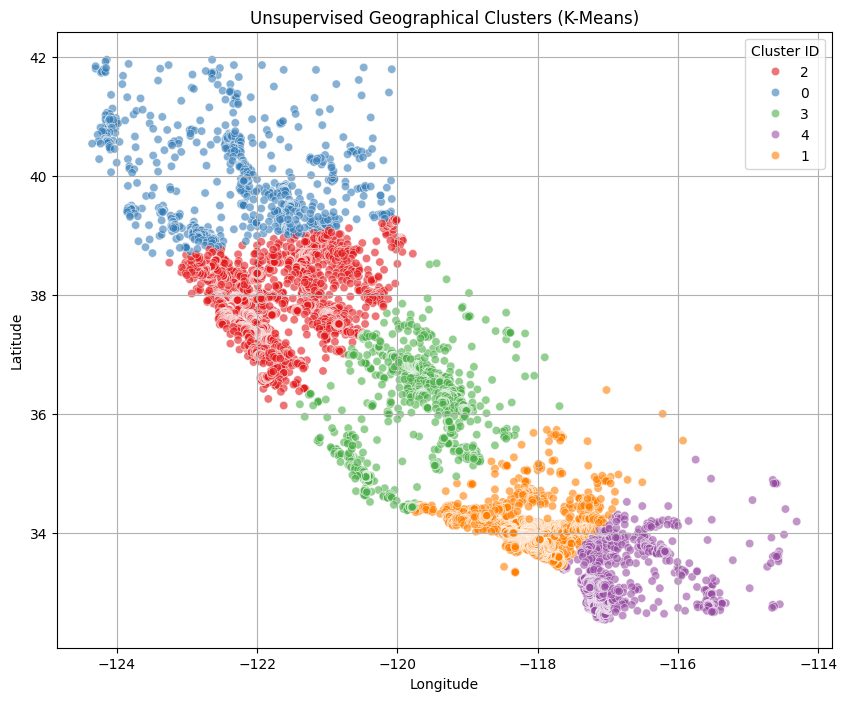

In [11]:
# Visualize the clusters geographically
plt.figure(figsize=(10, 8))
sns.scatterplot(data=housing_df, x='longitude', y='latitude', hue='geo_cluster', palette='Set1', alpha=0.6)
plt.title('Unsupervised Geographical Clusters (K-Means)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.show()

### 6. Loading a Pickle File
Let's locate and load the requested pickle file.

In [12]:
import os
import pickle
import glob

# Find all pickle files in the current workspace
pickle_files = glob.glob('**/*.pkl', recursive=True) + glob.glob('**/*.pickle', recursive=True)
print("Found pickle files:", pickle_files)

# If a pickle file is found, load the first one
if pickle_files:
    target_file = pickle_files[0]
    print(f"Loading {target_file}...")
    with open(target_file, 'rb') as f:
        loaded_data = pickle.load(f)
    print("Successfully loaded data description/preview:")
    if hasattr(loaded_data, 'head'):
        display(loaded_data.head())
    else:
        print(type(loaded_data))
        print(loaded_data)
else:
    print("No pickle files (.pkl or .pickle) were found in the workspace. Please upload your pickle file first!")

Found pickle files: []
No pickle files (.pkl or .pickle) were found in the workspace. Please upload your pickle file first!
